# Dimension Reduction and Representation Learning

This notebook compares PCA and a compact autoencoder using the same log-normalized HVG input and latent dimension. It reads saved outputs from the representation scripts and does not fit either method.

In [1]:
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import seaborn as sns
import umap
import yaml
from anndata import read_h5ad
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score


if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

with open("configs/default.yml") as file:
    config = yaml.safe_load(file)

settings = config["representation"]
seed = config["analysis"]["random_seed"]
sample_order = config["dataset"]["selected_samples"]
latent_dim = settings["latent_dim"]

if latent_dim is None:
    raise ValueError("Set representation.latent_dim after reviewing the PCA diagnostic.")

os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")


/Users/ren/anaconda3/envs/lung-tumor-cell-type-identification/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## PCA dimension selection

Centered PCA represents each cell as $z_i = W^T(x_i - \bar{x})$. The PCA script fits 100 components and saves their explained variance. The selected latent dimension is chosen from the elbow diagnostic before either final representation is exported.

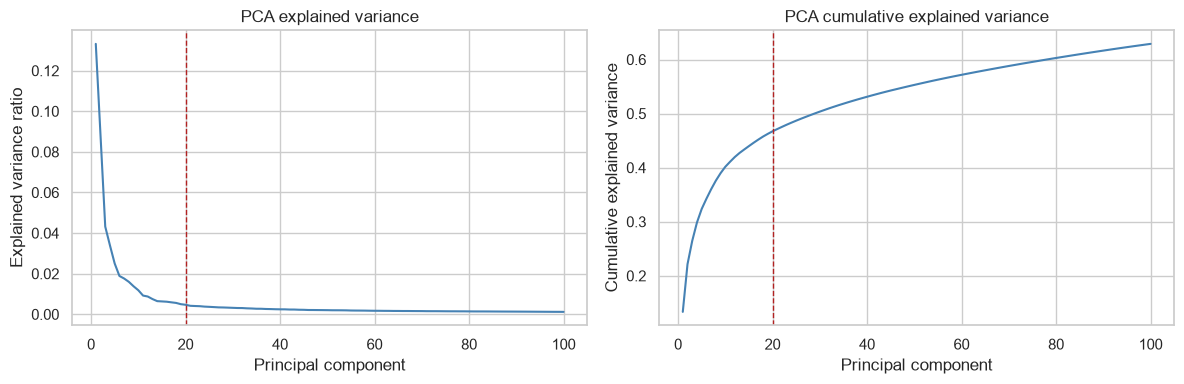

,component,explained_variance_ratio,cumulative_explained_variance
19,20,0.004683,0.467197


In [2]:
# Reuse the PCA diagnostic generated by the script rather than refitting PCA.
pca_variance = pd.read_csv("outputs/tables/pca-explained-variance.csv")
selected_variance = pca_variance.loc[pca_variance["component"] == latent_dim]

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(
    pca_variance["component"],
    pca_variance["explained_variance_ratio"],
    color="steelblue"
)
axes[0].axvline(latent_dim, color="firebrick", linestyle="--", linewidth=1)
axes[0].set_title("PCA explained variance")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")

axes[1].plot(
    pca_variance["component"],
    pca_variance["cumulative_explained_variance"],
    color="steelblue"
)
axes[1].axvline(latent_dim, color="firebrick", linestyle="--", linewidth=1)
axes[1].set_title("PCA cumulative explained variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative explained variance")

figure.tight_layout()
plt.show()

display(selected_variance)

The shared latent dimension keeps the downstream clustering comparison focused on the representation method rather than the number of dimensions retained.

## Autoencoder training

The autoencoder maps each input $x_i$ to $z_i = f_\theta(x_i)$ and reconstructs $\hat{x}_i = g_\phi(z_i)$. It minimizes mean squared reconstruction error, $n^{-1} \sum_i ||x_i - \hat{x}_i||_2^2$, on a training subset and uses a sample-stratified validation subset for early stopping.

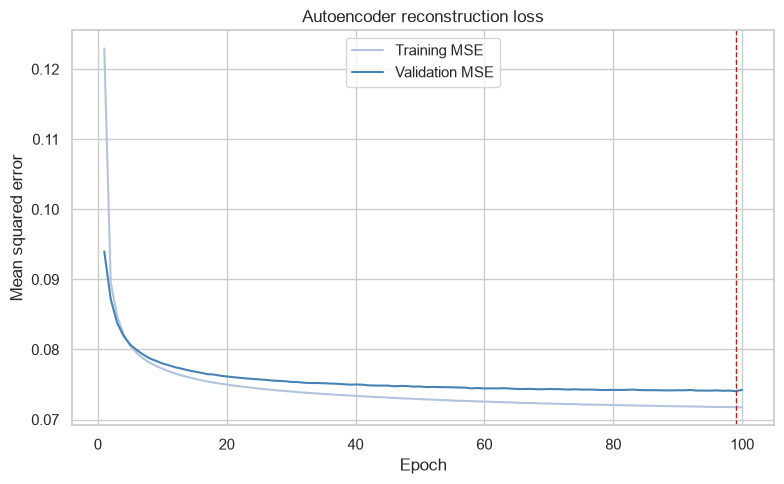

Best validation epoch: 99


In [3]:
# Identify the checkpoint epoch with the lowest validation reconstruction loss.
history = pd.read_csv("outputs/tables/autoencoder-training-history.csv")
best_epoch = history.loc[history["validation_mse"].idxmin(), "epoch"]

figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(history["epoch"], history["training_mse"], color="lightsteelblue", label="Training MSE")
axis.plot(history["epoch"], history["validation_mse"], color="steelblue", label="Validation MSE")
axis.axvline(best_epoch, color="firebrick", linestyle="--", linewidth=1)
axis.set_title("Autoencoder reconstruction loss")
axis.set_xlabel("Epoch")
axis.set_ylabel("Mean squared error")
axis.legend()

figure.tight_layout()
figure.savefig("outputs/figures/representation_training-loss.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Best validation epoch: {best_epoch}")

The checkpoint with the lowest validation loss is used to encode all cells. The loss curve assesses reconstruction learning only and is not directly comparable with PCA explained variance.

## Sample-effect diagnostics

Both embeddings are assessed without cell-type labels. A sample silhouette score uses sample identity as the grouping variable. A larger positive score indicates that cells from the same sample are more separated in the embedding, which is evidence of a stronger sample effect rather than better biological performance.

In [4]:
# Load the saved embeddings and their sample metadata.
adata = read_h5ad("data/processed/lung_tumor_hvg.h5ad", backed="r")
metadata = adata.obs[["sample"]].copy()
metadata["sample"] = pd.Categorical(metadata["sample"], categories=sample_order, ordered=True)

pca_embedding = pd.read_csv(
    f"outputs/embeddings/pca-{latent_dim}.csv.gz",
    index_col="cell_id"
)
autoencoder_embedding = pd.read_csv(
    f"outputs/embeddings/autoencoder-{latent_dim}.csv.gz",
    index_col="cell_id"
)
pca_embedding = pca_embedding.loc[metadata.index]
autoencoder_embedding = autoencoder_embedding.loc[metadata.index]

# Use the same seeded subset to compare sample-level separation in both embeddings.
sample_size = min(settings["silhouette_sample_size"], len(metadata))
pca_silhouette = silhouette_score(
    pca_embedding,
    metadata["sample"],
    sample_size=sample_size,
    random_state=seed
)
autoencoder_silhouette = silhouette_score(
    autoencoder_embedding,
    metadata["sample"],
    sample_size=sample_size,
    random_state=seed
)

summary = pd.DataFrame({
    "method": ["PCA", "Autoencoder"],
    "cells": [len(metadata), len(metadata)],
    "input_features": [adata.n_vars, adata.n_vars],
    "latent_dimensions": [pca_embedding.shape[1], autoencoder_embedding.shape[1]],
    "sample_silhouette_score": [pca_silhouette, autoencoder_silhouette],
    "pca_cumulative_explained_variance": [selected_variance["cumulative_explained_variance"].iloc[0], np.nan],
    "best_validation_mse": [np.nan, history["validation_mse"].min()]
})
summary.round(4).to_csv("outputs/tables/representation-summary.csv", index=False)

display(summary.round(4))

,method,cells,input_features,latent_dimensions,sample_silhouette_score,pca_cumulative_explained_variance,best_validation_mse
0,PCA,44180,2000,20,-0.0381,0.4672,NaN
1,Autoencoder,44180,2000,20,-0.0327,NaN,0.0741


## UMAP visualization

UMAP is applied separately to the saved PCA and autoencoder embeddings for visualization only. The same settings and sample color mapping are used for both panels.

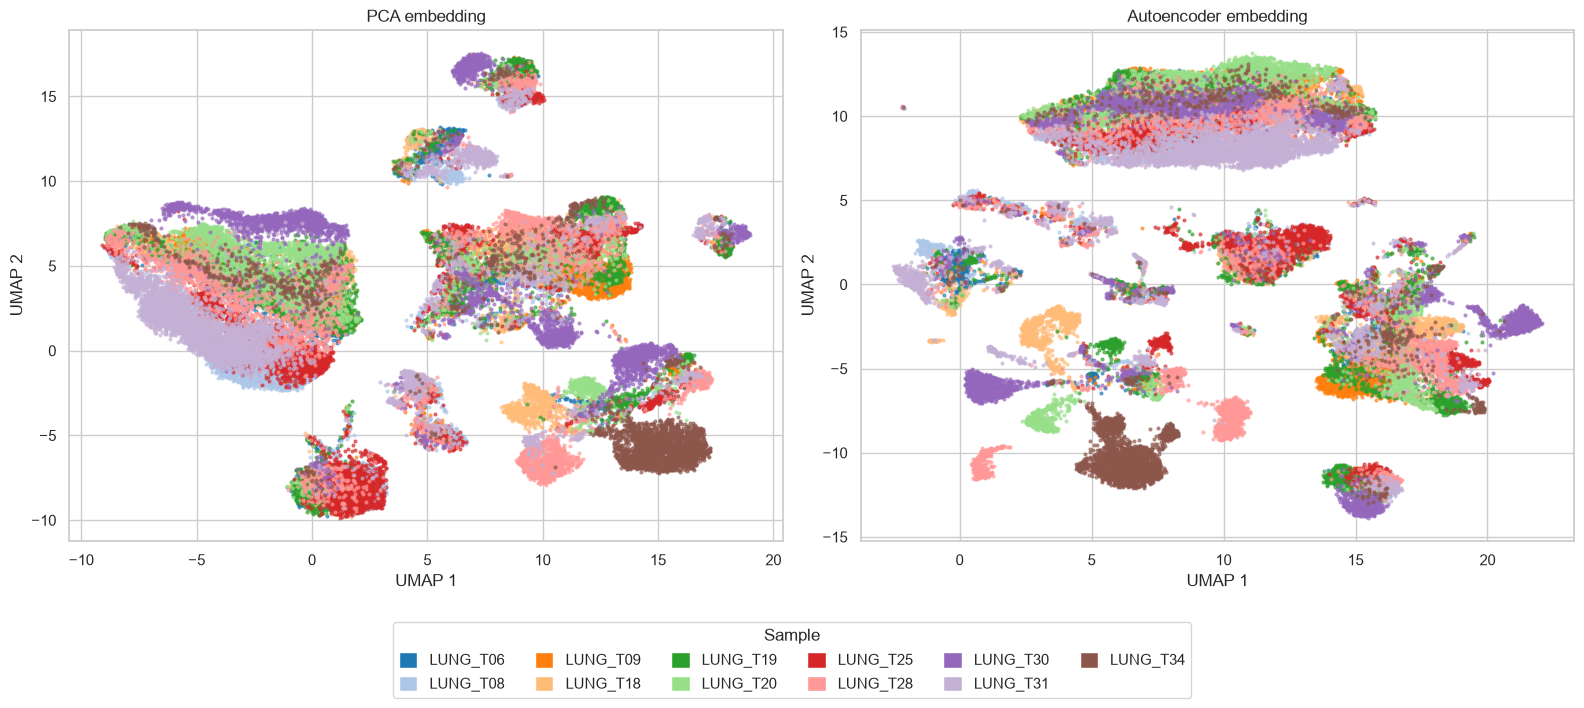

In [5]:
def calculate_umap(embedding):
    # Hold the UMAP settings fixed when comparing the two learned representations.
    reducer = umap.UMAP(
        n_neighbors=settings["umap_n_neighbors"],
        min_dist=settings["umap_min_dist"],
        random_state=seed,
        n_jobs=1,
        compatibility_layout=True
    )
    return reducer.fit_transform(embedding)


def plot_by_sample(axis, coordinates, title, x_label, y_label, plot_metadata):
    # Reuse the same sample order and colors across every visualization.
    for sample in sample_order:
        mask = plot_metadata["sample"].to_numpy() == sample
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=4,
            alpha=0.6,
            color=sample_colors[sample],
            label=sample
        )
    axis.set_title(title)
    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)


pca_umap = calculate_umap(pca_embedding)
autoencoder_umap = calculate_umap(autoencoder_embedding)
sample_colors = dict(zip(sample_order, sns.color_palette("tab20", len(sample_order))))

figure, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=False, sharey=False)
plot_by_sample(axes[0], pca_umap, "PCA embedding", "UMAP 1", "UMAP 2", metadata)
plot_by_sample(
    axes[1],
    autoencoder_umap,
    "Autoencoder embedding",
    "UMAP 1",
    "UMAP 2",
    metadata
)

legend_handles = [Patch(facecolor=sample_colors[sample]) for sample in sample_order]
figure.legend(
    legend_handles,
    sample_order,
    title="Sample",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=6,
    handlelength=1.2,
    handleheight=1.2
)
figure.tight_layout(rect=(0, 0.12, 1, 1))
figure.savefig("outputs/figures/representation_sample-umap.png", dpi=300, bbox_inches="tight")
plt.show()

## Comparing PCA, t-SNE, and UMAP visualization

PCA, t-SNE, and UMAP are compared using the complete autoencoder embedding. This isolates the visualization method from the representation method.

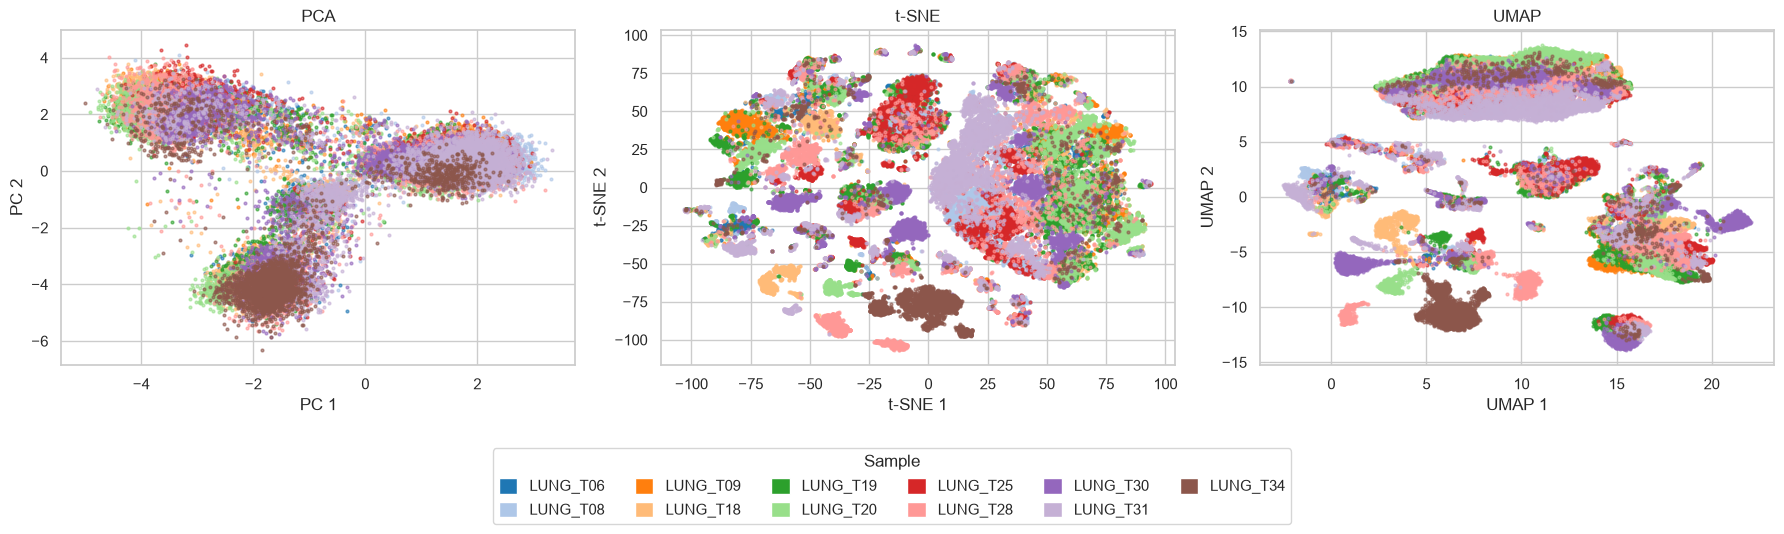

In [6]:
# Project one autoencoder embedding with three methods for a like-for-like visual comparison.
pca_projection = PCA(n_components=2, random_state=seed).fit_transform(autoencoder_embedding)
tsne_projection = TSNE(
    n_components=2,
    perplexity=settings["tsne_perplexity"],
    early_exaggeration=settings["tsne_early_exaggeration"],
    max_iter=settings["tsne_max_iter"],
    init="pca",
    learning_rate="auto",
    random_state=seed
).fit_transform(autoencoder_embedding)
umap_projection = calculate_umap(autoencoder_embedding)

figure, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, coordinates, title, x_label, y_label in zip(
    axes,
    [pca_projection, tsne_projection, umap_projection],
    ["PCA", "t-SNE", "UMAP"],
    ["PC 1", "t-SNE 1", "UMAP 1"],
    ["PC 2", "t-SNE 2", "UMAP 2"]
):
    plot_by_sample(axis, coordinates, title, x_label, y_label, metadata)

legend_handles = [Patch(facecolor=sample_colors[sample]) for sample in sample_order]
figure.legend(
    legend_handles,
    sample_order,
    title="Sample",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=6,
    handlelength=1.2,
    handleheight=1.2
)
figure.tight_layout(rect=(0, 0.12, 1, 1))
figure.savefig("outputs/figures/representation_visualization-comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Visualization hyperparameter sensitivity

The tuning script applies the same six t-SNE and six UMAP settings to the complete PCA and autoencoder embeddings. Each column uses the same setting in both rows, so the grids support a direct visual comparison of representation sensitivity.

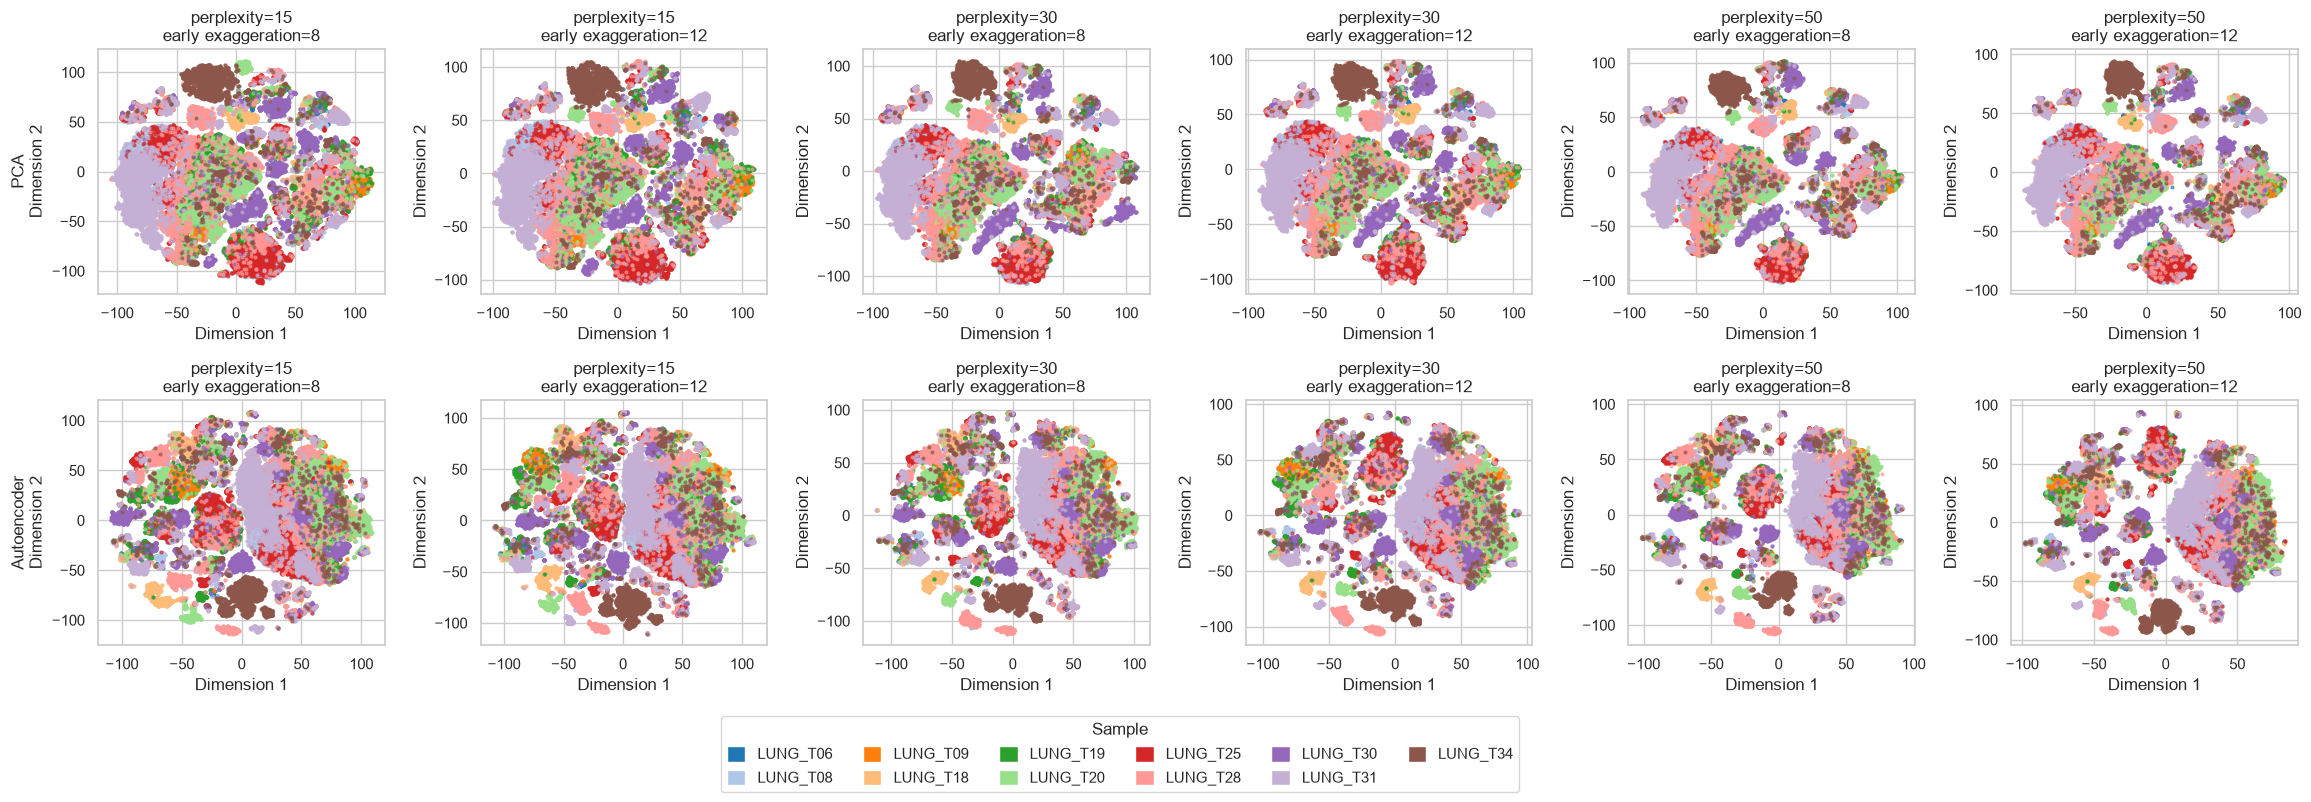

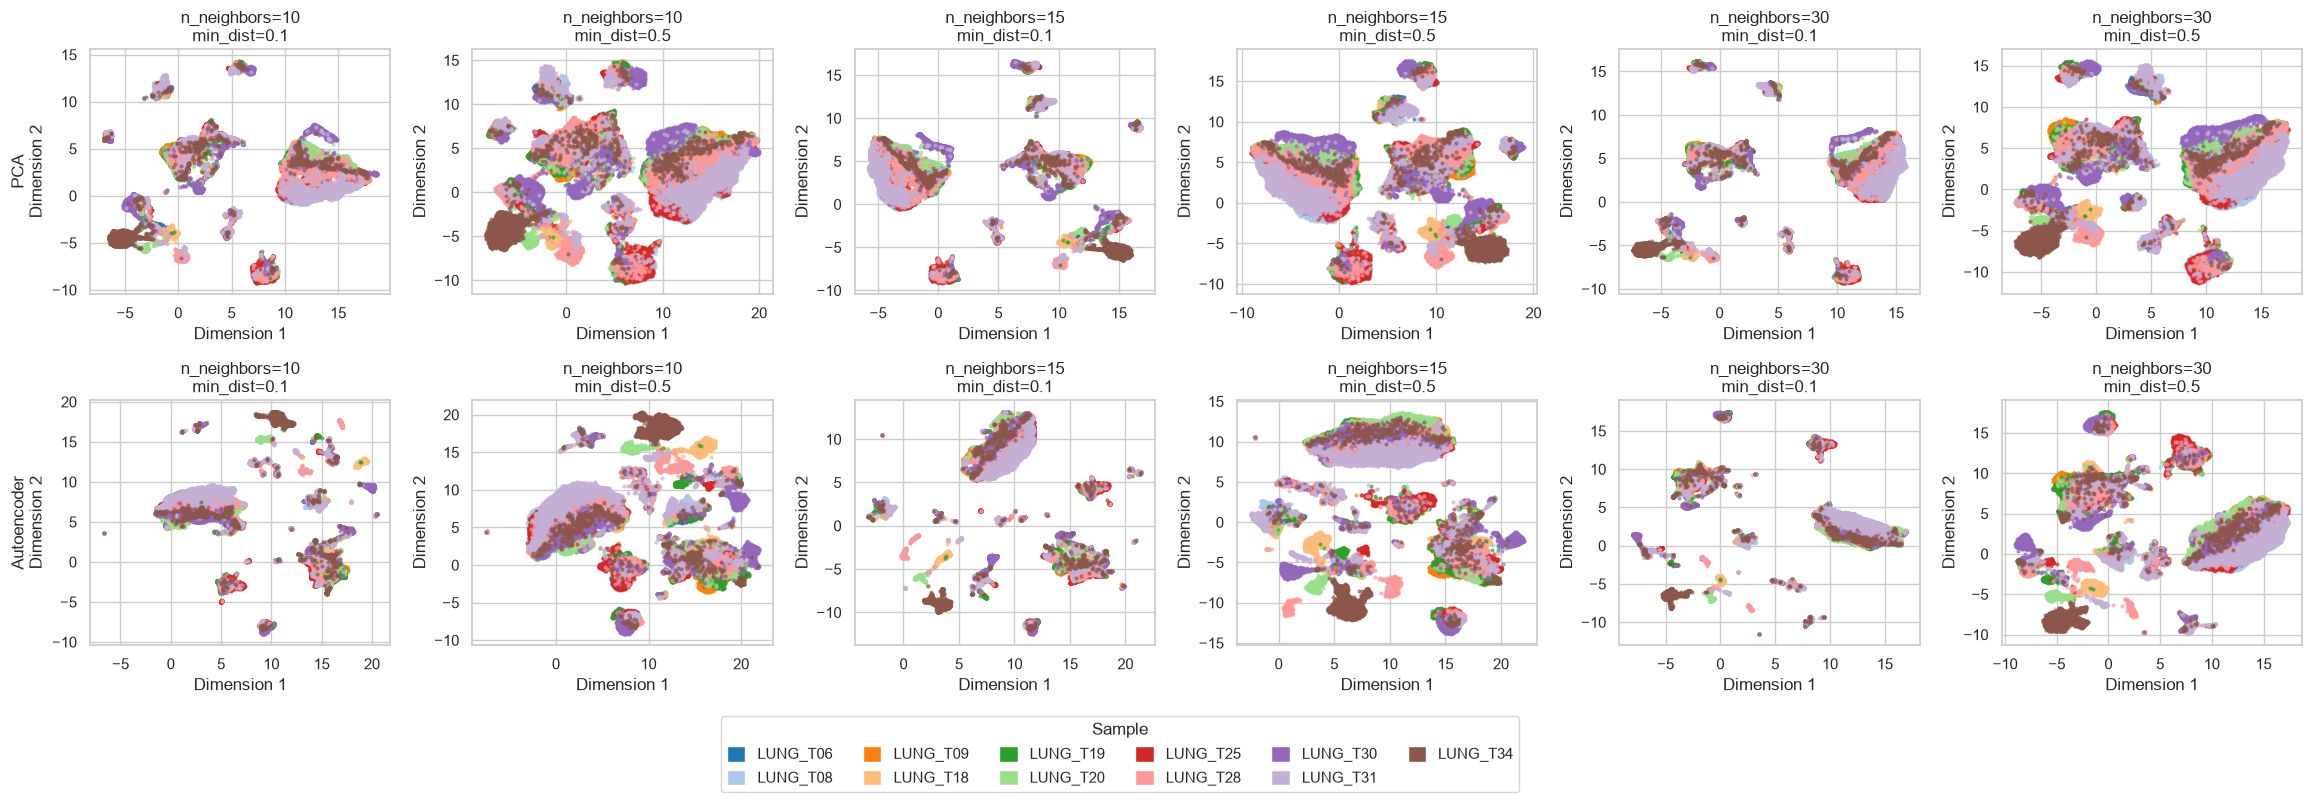

In [7]:
# Load the full-data coordinates generated by the parameter-grid script.
tuning_coordinates = np.load(
    "outputs/embeddings/visualization-tuning-coordinates.npz",
    allow_pickle=False
)

tuning_settings = config["visualization_tuning"]
tsne_settings = [
    (perplexity, early_exaggeration)
    for perplexity in tuning_settings["tsne_perplexities"]
    for early_exaggeration in tuning_settings["tsne_early_exaggerations"]
]
umap_settings = [
    (n_neighbors, min_dist)
    for n_neighbors in tuning_settings["umap_n_neighbors"]
    for min_dist in tuning_settings["umap_min_dists"]
]

def plot_tuning_grid(method, settings, output_file):
    # Each column fixes one setting while the two rows compare representations.
    figure, axes = plt.subplots(2, 6, figsize=(24, 8))

    for row, (representation, label) in enumerate([
        ("pca", "PCA"),
        ("autoencoder", "Autoencoder")
    ]):
        for column, (first_parameter, second_parameter) in enumerate(settings):
            if method == "tsne":
                setting_id = f"{representation}_tsne_p{first_parameter}_e{second_parameter}"
                title = f"perplexity={first_parameter}\nearly exaggeration={second_parameter}"
            else:
                min_dist = str(second_parameter).replace(".", "")
                setting_id = f"{representation}_umap_n{first_parameter}_d{min_dist}"
                title = f"n_neighbors={first_parameter}\nmin_dist={second_parameter:g}"

            y_label = f"{label}\nDimension 2" if column == 0 else "Dimension 2"
            plot_by_sample(
                axes[row, column],
                tuning_coordinates[setting_id],
                title,
                "Dimension 1",
                y_label,
                metadata
            )

    legend_handles = [Patch(facecolor=sample_colors[sample]) for sample in sample_order]
    figure.legend(
        legend_handles,
        sample_order,
        title="Sample",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.01),
        ncol=6,
        handlelength=1.2,
        handleheight=1.2
    )
    figure.tight_layout(rect=(0.03, 0.10, 1, 1))
    figure.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()


plot_tuning_grid(
    "tsne",
    tsne_settings,
    "outputs/figures/representation_tsne-hyperparameter-grid.png"
)
plot_tuning_grid(
    "umap",
    umap_settings,
    "outputs/figures/representation_umap-hyperparameter-grid.png"
)

UMAP remains the primary visualization for this project because it preserves local neighborhoods while giving a useful overview of the global arrangement. From the paired grids, the default UMAP hyperparameter setting is a reasonable choice for this dataset.